%pip install awscli
%pip install boto3

import os
import sys

!git clone https://${github_astro_guard_token}@github.com/zLPrime/astro-guard.git

In [1]:
import os
import sys

sys.path.append('./astro-guard/ml-workbench')

# Эксперимент 11: ширина 400, 10000 объектов на класс, magerr, 6 слоев, batchnorm, dropout

In [2]:
from astro_data import dataloader
from sklearn.preprocessing import LabelEncoder
import random

random.seed(42)
label_encoder = LabelEncoder()
best_model_path='models/experiment11.pth'
log_file = 'experiment11.log'
vector_length = 400
batch_size = 64
use_random_filter = False

dataset = dataloader.get_jd_magn_magerr_1d_dataset(
    os.environ['aws_access_key_id'],
    os.environ['aws_secret_access_key'], label_encoder,
    cache_path='./astro-guard/ml-workbench/astro_data/objects_cache.json',
    items_per_label=10000)

Loading object keys from cache...
items per label 10000
items per label 10000


In [3]:
import pandas as pd
import numpy as np
import torch
import torchvision.transforms as transforms

def _get_jd_magn_magerr_1d(df: pd.DataFrame, width: int = 400):
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.dropna(how='any', inplace=True)
    
    x_vals = df['mjd'].to_numpy()
    mag_vals = df['mag'].to_numpy()
    magerr_vals = df['magerr'].to_numpy()

    if len(x_vals) < 2:
        raise ValueError("Need at least two data points.")

    # Normalize x to [0, 1] and interpolate y values over fixed-width samples
    x_norm = (x_vals - x_vals.min()) / (x_vals.max() - x_vals.min())
    interp_points = np.linspace(0, 1, width)

    mag_interp = np.interp(interp_points, x_norm, mag_vals)
    magerr_interp = np.interp(interp_points, x_norm, magerr_vals)

    # Sanity checks
    if (
        np.isnan(mag_interp).any() or np.isinf(mag_interp).any() or
        np.isclose(mag_interp.max(), mag_interp.min()) #or
        # np.isnan(magerr_interp).any() or np.isinf(magerr_interp).any() or
        # np.isclose(magerr_interp.max(), magerr_interp.min())
    ):
        raise ValueError("Bad data: NaNs, Infs, or flat signal")

    # Normalize mag
    mag_norm = (mag_interp - mag_interp.min()) / (mag_interp.max() - mag_interp.min())

    # Normalize and invert magerr, or fallback to zeros
    if (
        np.isnan(magerr_interp).any() or np.isinf(magerr_interp).any() or
        np.isclose(magerr_interp.max(), magerr_interp.min())
    ):
        magerr_inverted = np.zeros_like(magerr_interp)
    else:
        magerr_norm = (magerr_interp - magerr_interp.min()) / (magerr_interp.max() - magerr_interp.min())
        magerr_inverted = 1.0 - magerr_norm

    stacked = np.stack([mag_norm, magerr_inverted], axis=0)  # Shape: (2, width)
    return torch.tensor(stacked, dtype=torch.float32)

transform = transforms.Compose([
    transforms.Lambda(_get_jd_magn_magerr_1d)
])

ztf_dataset = dataloader.AstroFileDataset('ztf_lightcurves', transform, label_encoder, 10000)

In [4]:
from torch.utils.data import random_split, Subset

target_class = label_encoder.transform(['nonvariables'])[0]

# Get indices for each subset
nonvariables_indices = dataset.get_class_indices('nonvariables')
variables_indices = dataset.get_class_indices('variables')

# Create subsets
nonvariables_subset = Subset(dataset, nonvariables_indices)
variables_subset = Subset(dataset, variables_indices)

dataset_size = len(variables_subset)
smaller_size = 1000 # тот же размер, что в первом эксперименте
larger_size = dataset_size - smaller_size

smaller_variables_dataset, larger_variables_dataset = random_split(variables_subset, [smaller_size, larger_size])

smaller_dataset = torch.utils.data.ConcatDataset([nonvariables_subset, smaller_variables_dataset])

train_dataloader, test_dataloader = dataloader.get_train_test(smaller_dataset, batch_size=batch_size)
train_dataset = torch.utils.data.ConcatDataset([train_dataloader.dataset, larger_variables_dataset, ztf_dataset])
train_dataloader, _ = dataloader.get_train_test(train_dataset, split_ratio=1.0, batch_size=batch_size)

In [5]:
from astro_model.model import JDLightCurve1DCNN6LBatchNormDropout
from astro_train.trainer import train_and_monitor
from torch import cuda

model = JDLightCurve1DCNN6LBatchNormDropout(2, in_channels=2)
device = 'cuda' if cuda.is_available() else 'cpu'

In [6]:
train_and_monitor(model, train_dataloader, 100, device=device, val_loader=test_dataloader, best_model_path=best_model_path, patience=10, log_file=log_file)

Epoch 1/100: 100%|██████████| 296/296 [03:11<00:00,  1.55it/s, Train Loss=0.1389, Train Acc=95.11%]


Validation Loss: 1.0575 | Validation Accuracy: 55.98%
Best model saved with accuracy: 55.98%


Epoch 2/100: 100%|██████████| 296/296 [00:49<00:00,  5.98it/s, Train Loss=0.1110, Train Acc=95.97%]


Validation Loss: 1.0360 | Validation Accuracy: 60.80%
Best model saved with accuracy: 60.80%


Epoch 3/100: 100%|██████████| 296/296 [00:48<00:00,  6.05it/s, Train Loss=0.1076, Train Acc=96.05%]


Validation Loss: 0.8312 | Validation Accuracy: 60.63%


... (30 outputs left out)

Epoch 19/100: 100%|██████████| 296/296 [00:48<00:00,  6.15it/s, Train Loss=0.0833, Train Acc=96.72%]


Validation Loss: 0.8307 | Validation Accuracy: 60.63%


Epoch 20/100: 100%|██████████| 296/296 [00:48<00:00,  6.17it/s, Train Loss=0.0843, Train Acc=96.71%]


Validation Loss: 1.0191 | Validation Accuracy: 51.16%
Early stopping triggered at epoch 20


In [8]:
from astro_test.test import print_evaluate
import torch

model.load_state_dict(torch.load(best_model_path, weights_only=True))

print_evaluate(model, test_dataloader, label_encoder, device)

100%|██████████| 10/10 [00:02<00:00,  4.23it/s]


Accuracy: 0.7242524916943521
Classification Report:
               precision    recall  f1-score   support

nonvariables       0.67      0.82      0.74       282
   variables       0.80      0.64      0.71       320

    accuracy                           0.72       602
   macro avg       0.73      0.73      0.72       602
weighted avg       0.74      0.72      0.72       602



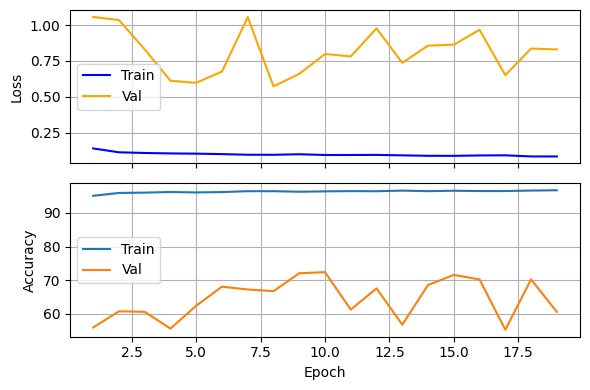

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(log_file)

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(6, 4))

ax1.plot(df['epoch'], df['train_loss'], label='Train', color='blue')
ax1.plot(df['epoch'], df['val_loss'], label='Val', color='orange')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(df['epoch'], df['train_acc'], label='Train')
ax2.plot(df['epoch'], df['val_acc'], label='Val')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()